In [ ]:
# ------------------------------------------------------
# --------------- Play with Output! -------------------
# ------------------------------------------------------
# The purpose of this script is to play with some 
# ECCO-Darwin output to figure out what is going on and
# where and how and all the things! Trés exploratory!
#
# Notes:
# - Needs to run in ecco-darwin conda env
#
# -----------------------------------------------------

In [35]:
# Load in the packages
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import xmitgcm
import ecco_v4_py as ecco
import MITgcmutils
import cmocean

## ECCO Darwin Output Files
 See here for legit/official/useful info: https://xmitgcm.readthedocs.io/en/latest/usage.html 

- STDOUT.* :
- STDERR.* :
- CO2_budg_2d.0000002192.data:
- CO2_budg_2d.0000002192.meta: 


#### <span style="color:deeppink"> Tracers </span>

In [ ]:
# Read in the tracers
tracer_01 = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/pickup_ptracers.0000000001'
tracer_data, tracer_its, tracer_meta = MITgcmutils.mds.rdmds(fnamearg=tracer_01, returnmeta=True)


In [46]:
tracer_meta

{'ndims': [3],
 'dataprec': ['float64'],
 'nrecords': [32],
 'nflds': [32],
 'fldlist': ['pTr01',
  'pTr02',
  'pTr03',
  'pTr04',
  'pTr05',
  'pTr06',
  'pTr07',
  'pTr08',
  'pTr09',
  'pTr10',
  'pTr11',
  'pTr12',
  'pTr13',
  'pTr14',
  'pTr15',
  'pTr16',
  'pTr17',
  'pTr18',
  'pTr19',
  'pTr20',
  'pTr21',
  'pTr22',
  'pTr23',
  'pTr24',
  'pTr25',
  'pTr26',
  'pTr27',
  'pTr28',
  'pTr29',
  'pTr30',
  'pTr31',
  'pTr32'],
 'dimlist': [46, 68, 44],
 'timestepnumber': [78912],
 'timeinterval': [[94694400.0]]}

Copied names and units for tracers from data.ptracers:  

PTRACERS_names( 1)= 'DIC',    
 PTRACERS_names( 2)= 'NO3',    
 PTRACERS_names( 3)= 'NO2',    
 PTRACERS_names( 4)= 'NH4',    
 PTRACERS_names( 5)= 'PO4',    
 PTRACERS_names( 6)= 'FeT',    
 PTRACERS_names( 7)= 'SiO2',    
 PTRACERS_names( 8)= 'DOC',    
 PTRACERS_names( 9)= 'tDOC',    
 PTRACERS_names(10)= 'DON',    
 PTRACERS_names(11)= 'DOP',    
 PTRACERS_names(12)= 'DOFe',    
 PTRACERS_names(13)= 'POC',    
 PTRACERS_names(14)= 'PON',    
 PTRACERS_names(15)= 'POP',    
 PTRACERS_names(16)= 'POFe',    
 PTRACERS_names(17)= 'POSi',    
 PTRACERS_names(18)= 'PIC',    
 PTRACERS_names(19)= 'ALK',    
 PTRACERS_names(20)= 'O2',    
 PTRACERS_names(21)= 'c01',    
 PTRACERS_names(22)= 'c02',    
 PTRACERS_names(23)= 'c03',    
 PTRACERS_names(24)= 'c04',    
 PTRACERS_names(25)= 'c05',    
 PTRACERS_names(26)= 'c06',    
 PTRACERS_names(27)= 'c07',    
 PTRACERS_names(28)= 'Chl01',    
 PTRACERS_names(29)= 'Chl02',    
 PTRACERS_names(30)= 'Chl03',    
 PTRACERS_names(31)= 'Chl04',    
 PTRACERS_names(32)= 'Chl05',    
#
 PTRACERS_units( 1)= 'uM C'    
 PTRACERS_units( 2)= 'uM N'    
 PTRACERS_units( 3)= 'uM N'    
 PTRACERS_units( 4)= 'uM N'    
 PTRACERS_units( 5)= 'uM P'    
 PTRACERS_units( 6)= 'uM Fe'    
 PTRACERS_units( 7)= 'uM Si'    
 PTRACERS_units( 8)= 'uM C'    
 PTRACERS_units( 9)= 'uM C'    
 PTRACERS_units(10)= 'uM N'    
 PTRACERS_units(11)= 'uM P'    
 PTRACERS_units(12)= 'uM Fe'    
 PTRACERS_units(13)= 'uM C'    
 PTRACERS_units(14)= 'uM N'    
 PTRACERS_units(15)= 'uM P'    
 PTRACERS_units(16)= 'uM Fe'    
 PTRACERS_units(17)= 'uM Si'    
 PTRACERS_units(18)= 'uM C'    
 PTRACERS_units(19)= 'meq/m^3'    
 PTRACERS_units(20)= 'uM O'    
 PTRACERS_units(21)= 'uM C'    
 PTRACERS_units(22)= 'uM C'    
 PTRACERS_units(23)= 'uM C'    
 PTRACERS_units(24)= 'uM C'    
 PTRACERS_units(25)= 'uM C'    
 PTRACERS_units(26)= 'uM C'    
 PTRACERS_units(27)= 'uM C'    
 PTRACERS_units(28)= 'mg/m^3'    
 PTRACERS_units(29)= 'mg/m^3'    
 PTRACERS_units(30)= 'mg/m^3'    
 PTRACERS_units(31)= 'mg/m^3'    
 PTRACERS_units(32)= 'mg/m^3'    

In [ ]:
# What is the shape of the tracers?
#[32, 44, 68, 46] = [tracer, z, x?, y?] (all for one time step)
# llc270 has 44 evenly-spaced verticla levels, x and y are for the llc20 tile 
# so x is actually decreasing latitude and y is longitude 
np.shape(tracer_data)

(32, 44, 68, 46)

Text(0.5, 1.0, 'FeT (uM Fe)')

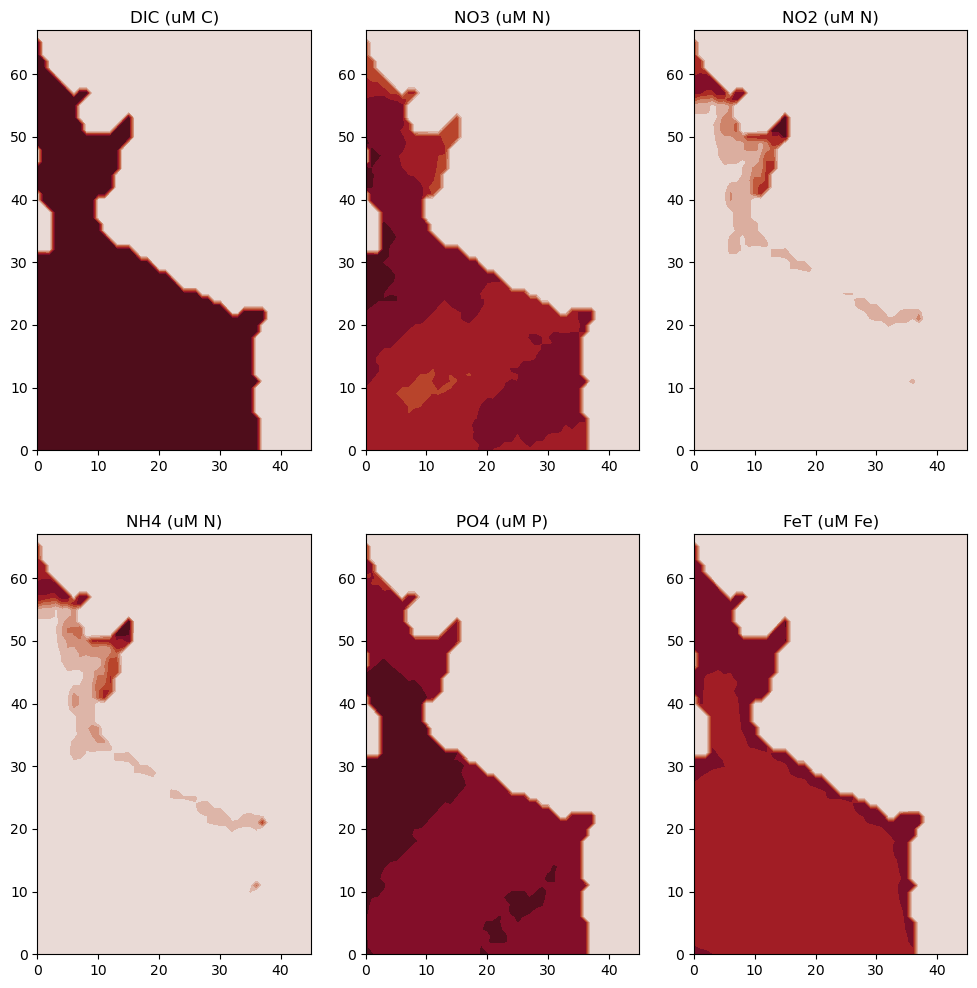

In [ ]:
# Try to plot this?

# Set the vertical level
z_lev = 10

# Set the titles 
tracer_name = ['DIC', 'NO3', 'NO2', 'NH4', 'PO4', 'FeT']

# Make the figure
fig, ax = plt.subplots(2, 3, figsize=(12,12))

# Tracer 01 = DIC
cs1 = ax[0,0].contourf(tracer_data[0,z_lev,:,:], cmap=cmocean.cm.amp)
ax[0,0].set_title('DIC (uM C)')
#ax[0,0].yaxis.set_inverted(True)
# Tracer 02 = NO3
cs1 = ax[0,1].contourf(tracer_data[1,z_lev,:,:], cmap=cmocean.cm.amp)
ax[0,1].set_title('NO3 (uM N)')
# Tracer 03 = NO2
cs1 = ax[0,2].contourf(tracer_data[2,z_lev,:,:], cmap=cmocean.cm.amp)
ax[0,2].set_title('NO2 (uM N)')
# Tracer 04 = NH4
cs1 = ax[1,0].contourf(tracer_data[3,z_lev,:,:], cmap=cmocean.cm.amp)
ax[1,0].set_title('NH4 (uM N)')
# Tracer 05 = PO4
cs1 = ax[1,1].contourf(tracer_data[4,z_lev,:,:], cmap=cmocean.cm.amp)
ax[1,1].set_title('PO4 (uM P)')
# Tracer 06 = FeT
cs1 = ax[1,2].contourf(tracer_data[5,z_lev,:,:], cmap=cmocean.cm.amp)
ax[1,2].set_title('FeT (uM Fe)')

# Add colorbars 

Okay! So I think this is showing the different concentrations of the tracers at one time step (the one loaded above) at vertical level 10 (with 1 being the top of the water column/opposite of ROMS I think). I think it is oriented in the same way as Tile 6 in llc270 (https://ecco-v4-python-tutorial.readthedocs.io/ECCO_v4_Interpolating_Fields_to_LatLon_Grid.html). So north is to the left in the orientation of these plots!

In [ ]:
# Can we plot this on a map with lat lon?

#### <span style="color:Blue"> Sea Ice </span>

In [51]:
# Read in sea ice things
sea_ice_01 = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run/pickup_seaice.0000000001'
sea_ice_data, sea_ice_its, sea_ice_meta = MITgcmutils.mds.rdmds(fnamearg=sea_ice_01, returnmeta=True)

In [52]:
sea_ice_meta

{'ndims': [2],
 'dataprec': ['float64'],
 'nrecords': [6],
 'nflds': [6],
 'fldlist': ['siTICE', 'siAREA', 'siHEFF', 'siHSNOW', 'siUICE', 'siVICE'],
 'dimlist': [46, 68],
 'timestepnumber': [78841],
 'timeinterval': [[94609200.0]]}

In [ ]:
# Print the shape of the data
np.shape(sea_ice_data)

(6, 68, 46)

Text(0.5, 1.0, 'V Ice Velocity ()')

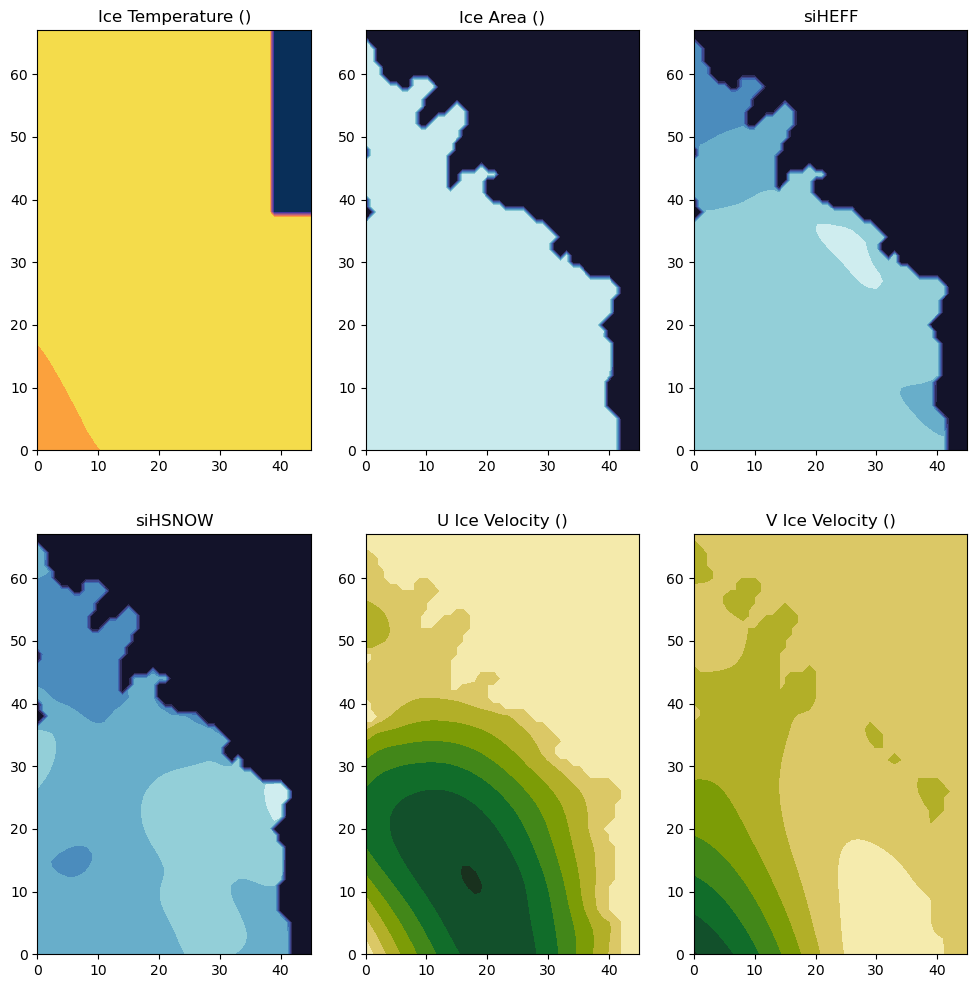

In [ ]:
# Make a plot of the things
# Make the figure
fig, ax = plt.subplots(2, 3, figsize=(12,12))

# Tracer 01 = DIC
cs1 = ax[0,0].contourf(sea_ice_data[0,:,:], cmap=cmocean.cm.thermal)
ax[0,0].set_title('Ice Temperature ()')
#ax[0,0].yaxis.set_inverted(True)
# Tracer 02 = NO3
cs1 = ax[0,1].contourf(sea_ice_data[1,:,:], cmap=cmocean.cm.ice)
ax[0,1].set_title('Ice Area ()')
# Tracer 03 = NO2
cs1 = ax[0,2].contourf(sea_ice_data[2,:,:], cmap=cmocean.cm.ice)
ax[0,2].set_title('siHEFF')
# Tracer 04 = NH4
cs1 = ax[1,0].contourf(sea_ice_data[3,:,:], cmap=cmocean.cm.ice)
ax[1,0].set_title('siHSNOW')
# Tracer 05 = PO4
cs1 = ax[1,1].contourf(sea_ice_data[4,:,:], cmap=cmocean.cm.speed)
ax[1,1].set_title('U Ice Velocity ()')
# Tracer 06 = FeT
cs1 = ax[1,2].contourf(sea_ice_data[5,:,:], cmap=cmocean.cm.speed)
ax[1,2].set_title('V Ice Velocity ()')

# Add colorbars 


#### <span style="color:yellow"> Not Working but Maybe Useful Later </span>

In [ ]:
# Load in the model output? (this does not work)
# Where/what is the output...
data_dir = '/Users/bundzis/Desktop/Research/Arctic_sed_ECCO/Repos/ecco_darwin/regions/mac_delta/llc270/biogeochem_setup/carroll_2020_ecosystem/ED-SBS_Bertin_etal_2023/darwin3_v67x/run'

# Load with xmitgcm
model_output = xmitgcm.open_mdsdataset(data_dir=data_dir, prefix=['pickup', 'pickup_darwin'])


In [ ]:
# Look at it 
# Is it global? What are the coordinates? Is it giant?